# 21. Station map and table

The network on 2026-05-29 relative to LC-36, with each station's status for the explosion (from notebook 22's
channel-status analysis): working infrasound and seismic channels, dead stations, and the launch pads.
Distances and azimuths are from LC-36 (`cfg.station_table`). The Gem and SmartSolo sites of the Artemis II
deployment (recovered in April) are shown faintly for reference.

Output (`cfg.OUT_DIR / "21_station_map"`): `station_map.png`, `station_map.pdf`, `station_table.csv`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import newglenn_config as cfg
OUT = cfg.output_dir('21_station_map')
st = cfg.station_table()
pads = pd.read_excel(cfg.EVENT.station_file, sheet_name=cfg.EVENT.site_sheet).set_index('pad')
STATUS = {'B20': 'infraBSU DD1, Trillium (noisy), Chaparral (clipped, faulty)', 'B14': '3 infraBSUs, Trillium',
          'B29': 'infraBSU DD0, Trillium', 'B05': 'infraBSU DD0, Trillium (Z, DH1)',
          'B01': 'no sensors connected', 'B03': 'no sensors (faulty Centaur)', 'B24': 'no sensors connected'}
tab = st.loc[list(STATUS)].copy()
tab['status'] = pd.Series(STATUS)
tab = tab.sort_values('distance_km')
tab[['lat', 'lon', 'distance_km', 'azimuth_deg', 'status']].round(4).to_csv(OUT / 'station_table.csv')
display(tab[['lat', 'lon', 'distance_km', 'azimuth_deg', 'status']].round(3))

,lat,lon,distance_km,azimuth_deg,status
station,,,,,
B20,28.574,-80.572,11.793,345.578,"infraBSU DD1, Trillium (noisy), Chaparral (cli..."
B24,28.581,-80.641,15.551,321.647,no sensors connected
B01,28.621,-80.607,17.867,339.339,no sensors connected
B14,28.632,-80.616,19.312,338.110,"3 infraBSUs, Trillium"
B03,28.643,-80.624,20.683,337.366,no sensors (faulty Centaur)
B29,28.618,-80.677,21.003,321.141,"infraBSU DD0, Trillium"
B05,28.640,-80.645,21.304,331.848,"infraBSU DD0, Trillium (Z, DH1)"


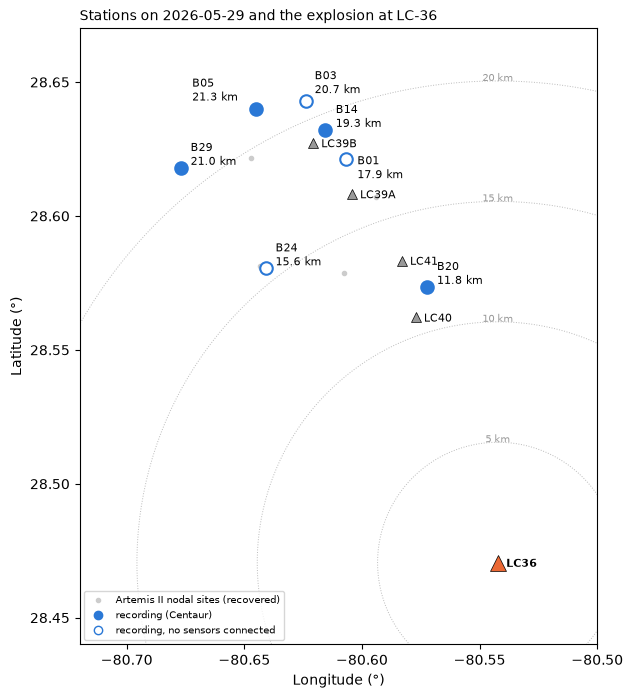

In [2]:
fig, ax = plt.subplots(figsize=(7, 8))
other = st.drop(index=list(STATUS), errors='ignore')
ax.plot(other.lon, other.lat, '.', color='#cccccc', ms=6, label='Artemis II nodal sites (recovered)')
for name, r in pads.iterrows():
    ax.plot(r.lon, r.lat, '^', color='#eb6834' if name == cfg.PAD else '#999999', ms=11 if name == cfg.PAD else 7,
            mec='k', mew=0.5)
    ax.annotate(name, (r.lon, r.lat), xytext=(6, -3), textcoords='offset points', fontsize=8,
                fontweight='bold' if name == cfg.PAD else 'normal')
for sta, r in tab.iterrows():
    dead = STATUS[sta].startswith('no sensors')
    ax.plot(r.lon, r.lat, 'o', mfc='white' if dead else '#2a78d6', mec='#2a78d6', ms=9, mew=1.5)
    off = {'B03': (6, 6), 'B05': (-46, 6), 'B01': (8, -14), 'B14': (8, 2)}.get(sta, (7, 2))
    ax.annotate(f'{sta}\n{r.distance_km:.1f} km', (r.lon, r.lat), xytext=off, textcoords='offset points', fontsize=8)
for rkm in (5, 10, 15, 20):
    a = np.linspace(0, 2 * np.pi, 361)
    dlat = rkm / 111.2 * np.cos(a); dlon = rkm / (111.2 * np.cos(np.radians(cfg.EVENT.site_lat))) * np.sin(a)
    ax.plot(cfg.EVENT.site_lon + dlon, cfg.EVENT.site_lat + dlat, ':', color='#bbbbbb', lw=0.7)
    ax.text(cfg.EVENT.site_lon, cfg.EVENT.site_lat + rkm / 111.2, f'{rkm} km', fontsize=7, color='#999999', ha='center')
ax.plot([], [], 'o', mfc='#2a78d6', mec='#2a78d6', label='recording (Centaur)')
ax.plot([], [], 'o', mfc='white', mec='#2a78d6', label='recording, no sensors connected')
ax.set(xlim=(-80.72, -80.50), ylim=(28.44, 28.67), xlabel='Longitude (°)', ylabel='Latitude (°)', aspect=1 / np.cos(np.radians(28.55)))
ax.set_xticks(np.arange(-80.70, -80.49, 0.05))
ax.legend(fontsize=7, loc='lower left')
ax.set_title('Stations on 2026-05-29 and the explosion at LC-36', fontsize=10, loc='left')
fig.savefig(OUT / 'station_map.png', dpi=200, bbox_inches='tight'); fig.savefig(OUT / 'station_map.pdf', bbox_inches='tight')